# Семинар 2-СС. Есептер жинағы

Бұл дәптерде 4 есеп шешіледі:
1. RGB → HSV түрлендіру
2. Гистограмманы қолмен теңестіру
3. Аффиндік түрлендіру матрицасы
4. Проективті түрлендіру (гомография)

In [12]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import os

OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)


## Есеп 1: RGB → HSV түрлендіру

**Берілгені:** пиксель $(R, G, B) = (255, 128, 0)$. HSV мәнін табу керек.

**Қадамдар:**
1. Нормалау: $R' = R/255,\ G' = G/255,\ B' = B/255$
2. $C_{max} = \max(R',G',B'),\ C_{min} = \min(R',G',B'),\ \Delta = C_{max}-C_{min}$
3. $V = C_{max}$
4. $S = \Delta / C_{max}$ (егер $C_{max} \ne 0$)
5. $H$ — қай канал максимал екеніне байланысты есептеледі

### Өз бетінше: (0, 200, 100) пикселін HSV-ге түрлендіру

In [13]:
def rgb_to_hsv_manual(r, g, b):
    """R, G, B — [0, 255] аралығында. Нәтиже: H (градус, 0-360), S (%), V (%)."""
    r_, g_, b_ = r / 255.0, g / 255.0, b / 255.0
    c_max = max(r_, g_, b_)
    c_min = min(r_, g_, b_)
    delta = c_max - c_min

    v = c_max
    s = 0.0 if c_max == 0 else delta / c_max

    if delta == 0:
        h = 0.0
    elif c_max == r_:
        h = 60 * (((g_ - b_) / delta) % 6)
    elif c_max == g_:
        h = 60 * (((b_ - r_) / delta) + 2)
    else:  # c_max == b_
        h = 60 * (((r_ - g_) / delta) + 4)

    return h, s * 100, v * 100


def hsv_to_opencv_scale(h, s_percent, v_percent):
    """OpenCV-де H 0-179 (яғни H/2), S мен V 0-255 масштабында сақталады."""
    return round(h / 2), round(s_percent / 100 * 255), round(v_percent / 100 * 255)

R2, G2, B2 = 0, 200, 100
h2, s2, v2 = rgb_to_hsv_manual(R2, G2, B2)
print(f"Қолмен есептеу: H={h2:.2f}°, S={s2:.2f}%, V={v2:.2f}%")

h2_cv, s2_cv, v2_cv = hsv_to_opencv_scale(h2, s2, v2)
print(f"OpenCV масштабында: ({h2_cv}, {s2_cv}, {v2_cv})")

px2 = np.uint8([[[B2, G2, R2]]])  # BGR!
hsv2_cv = cv2.cvtColor(px2, cv2.COLOR_BGR2HSV)
print("OpenCV нәтижесі (cv2.cvtColor):", hsv2_cv[0, 0])


Қолмен есептеу: H=150.00°, S=100.00%, V=78.43%
OpenCV масштабында: (75, 255, 200)
OpenCV нәтижесі (cv2.cvtColor): [ 75 255 200]


## Есеп 2: гистограмманы қолмен теңестіру

**Берілгені:** $4\times4$ кескін, 3 бит ($L=8$, деңгейлер $0..7$).

$$s_k = \text{round}((L-1)\cdot CDF(r_k)) = \text{round}(7\cdot CDF(r_k)), \quad N=16$$

In [14]:
img_small = np.array([
    [2, 3, 3, 4],
    [3, 4, 4, 5],
    [3, 4, 5, 6],
    [2, 4, 5, 6],
], dtype=np.uint8)

L = 8
N = img_small.size

# Гистограмма: әр деңгей үшін кездесу саны
levels = np.arange(L)
hist = np.array([(img_small == level).sum() for level in levels])

p = hist / N
cdf = np.cumsum(p)
sk = np.round((L - 1) * cdf).astype(int)

print(f"{'rk':>3} {'nk':>4} {'p(rk)':>8} {'CDF':>8} {'7*CDF':>8} {'sk':>4}")
for rk in levels:
    if hist[rk] == 0:
        continue
    print(f"{rk:>3} {hist[rk]:>4} {p[rk]:>8.4f} {cdf[rk]:>8.4f} {(L-1)*cdf[rk]:>8.4f} {sk[rk]:>4}")

# rk -> sk сәйкестік кестесі (mapping)
mapping = {rk: sk[rk] for rk in levels}
print("\nСәйкестік (mapping):", mapping)


 rk   nk    p(rk)      CDF    7*CDF   sk
  2    2   0.1250   0.1250   0.8750    1
  3    4   0.2500   0.3750   2.6250    3
  4    5   0.3125   0.6875   4.8125    5
  5    3   0.1875   0.8750   6.1250    6
  6    2   0.1250   1.0000   7.0000    7

Сәйкестік (mapping): {np.int64(0): np.int64(0), np.int64(1): np.int64(0), np.int64(2): np.int64(1), np.int64(3): np.int64(3), np.int64(4): np.int64(5), np.int64(5): np.int64(6), np.int64(6): np.int64(7), np.int64(7): np.int64(7)}


In [15]:
equalized = np.vectorize(mapping.get)(img_small)

print("Бастапқы кескін:")
print(img_small)
print("\nТеңестірілген кескін:")
print(equalized)

expected = np.array([
    [1, 3, 3, 5],
    [3, 5, 5, 6],
    [3, 5, 6, 7],
    [1, 5, 6, 7],
])
print("\nСлайдтағы күтілетін нәтижемен сәйкес пе?", np.array_equal(equalized, expected))


Бастапқы кескін:
[[2 3 3 4]
 [3 4 4 5]
 [3 4 5 6]
 [2 4 5 6]]

Теңестірілген кескін:
[[1 3 3 5]
 [3 5 5 6]
 [3 5 6 7]
 [1 5 6 7]]

Слайдтағы күтілетін нәтижемен сәйкес пе? True


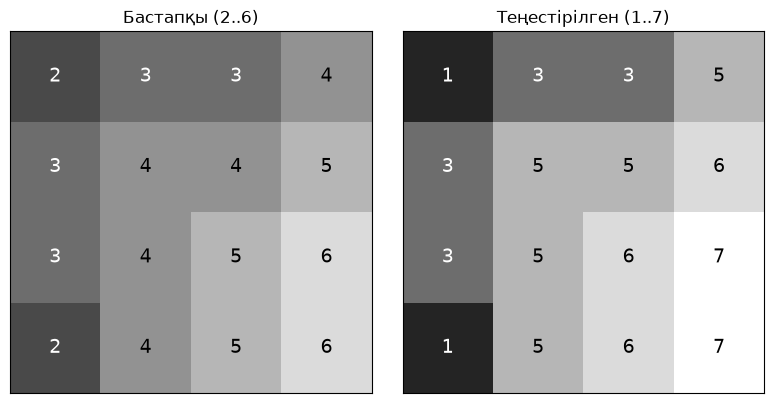

Қорытынды: [2...6] аралығы [1...7]-ге созылды, контраст артты. Бірақ деңгейлер саны өзгермейді — тек орындары ауысады.


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

for ax, data, title in zip(axes, [img_small, equalized], ["Бастапқы (2..6)", "Теңестірілген (1..7)"]):
    ax.imshow(data, cmap="gray", vmin=0, vmax=L - 1)
    ax.set_title(title)
    for i in range(4):
        for j in range(4):
            color = "white" if data[i, j] < L / 2 else "black"
            ax.text(j, i, str(data[i, j]), ha="center", va="center", color=color, fontsize=14)
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task2_histogram_equalization.png"), bbox_inches="tight", dpi=120)
plt.show()

print("Қорытынды: [2...6] аралығы [1...7]-ге созылды, контраст артты. "
      "Бірақ деңгейлер саны өзгермейді — тек орындары ауысады.")


## Есеп 3: аффиндік түрлендіру матрицасы

**Шарты:** $P=(100, 0)$ нүктесін $\theta=30°$-қа бұрып, $(20, 10)$-ға жылжыту керек.

$$M = \begin{bmatrix}\cos\theta & -\sin\theta & t_x \\ \sin\theta & \cos\theta & t_y\end{bmatrix}$$

In [17]:
theta_deg = 30
theta = np.deg2rad(theta_deg)
tx, ty = 20, 10

M = np.array([
    [np.cos(theta), -np.sin(theta), tx],
    [np.sin(theta),  np.cos(theta), ty],
])
print("M =")
print(np.round(M, 3))

P = np.array([100, 0, 1])  # біртекті координаталар (homogeneous)
P_new = M @ P
print(f"\nx' = {P_new[0]:.1f}")
print(f"y' = {P_new[1]:.1f}")
print(f"P' = ({P_new[0]:.1f}, {P_new[1]:.1f})  — слайдтағы (106.6, 60.0) мәнімен сәйкес")


M =
[[ 0.866 -0.5   20.   ]
 [ 0.5    0.866 10.   ]]

x' = 106.6
y' = 60.0
P' = (106.6, 60.0)  — слайдтағы (106.6, 60.0) мәнімен сәйкес


### OpenCV арқылы тексеру

Екі әдісті көрсетеміз: (1) `cv2.getRotationMatrix2D` — кескінді центр бойынша бұру, (2) `cv2.getAffineTransform` — 3 нүкте жұбы арқылы аффиндік матрицаны табу.

cv2.getRotationMatrix2D нәтижесі:
[[  0.866   0.5   -64.325]
 [ -0.5     0.866  79.936]]

cv2.getAffineTransform нәтижесі (3 нүкте бойынша):
[[ 1.   -0.05 10.  ]
 [ 0.1   1.   20.  ]]


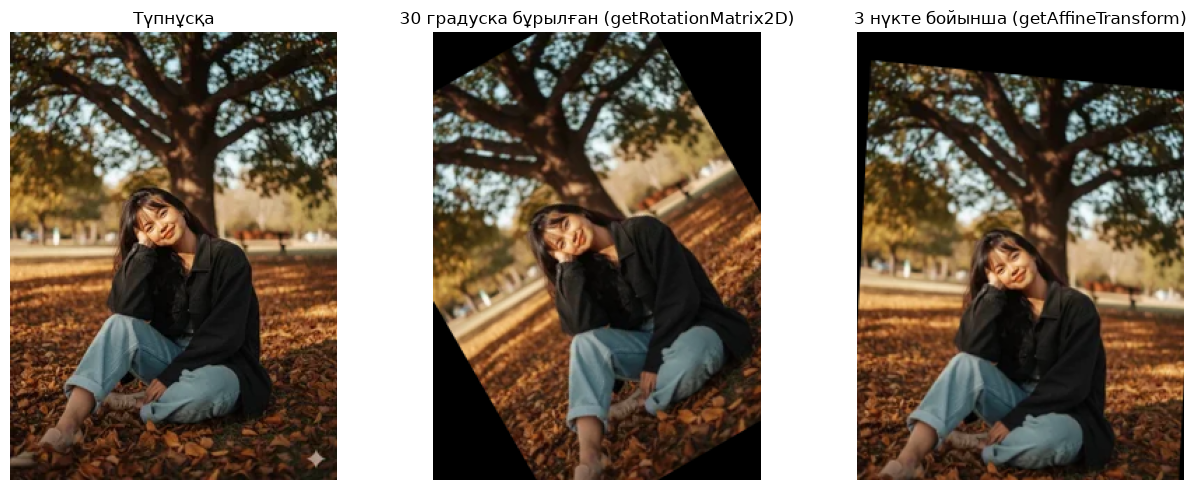

In [18]:
img = cv2.imread("images/photo.webp")
h, w = img.shape[:2]

# 1) Центрді айнала 30°-қа бұру (OpenCV: y осі төмен)
M_rot = cv2.getRotationMatrix2D((w / 2, h / 2), theta_deg, 1.0)
rot = cv2.warpAffine(img, M_rot, (w, h))

# 2) 3 нүкте бойынша аффиндік матрица
src = np.float32([[0, 0], [100, 0], [0, 100]])
dst = np.float32([[10, 20], [110, 30], [5, 120]])
A = cv2.getAffineTransform(src, dst)  # 2x3
out = cv2.warpAffine(img, A, (w, h))

print("cv2.getRotationMatrix2D нәтижесі:")
print(np.round(M_rot, 3))
print("\ncv2.getAffineTransform нәтижесі (3 нүкте бойынша):")
print(np.round(A, 3))

fig, axes = plt.subplots(1, 3, figsize=(13, 5))
for ax, im, title in zip(
    axes,
    [img, rot, out],
    ["Түпнұсқа", f"{theta_deg} градуска бұрылған (getRotationMatrix2D)", "3 нүкте бойынша (getAffineTransform)"],
):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task3_affine_transform.png"), bbox_inches="tight", dpi=120)
plt.show()


**Ескерту:** OpenCV-де оң бұрыш кескінде сағат тіліне қарсы бұрады; $y$ осі төмен бағытталғандықтан, $\sin$ таңбалары математикалық жазудан өзгеше болып көрінеді.

## Есеп 4: проективті түрлендіру (гомография)

$$x' = \frac{h_{11}x + h_{12}y + h_{13}}{h_{31}x + h_{32}y + 1}, \qquad y' = \frac{h_{21}x + h_{22}y + h_{23}}{h_{31}x + h_{32}y + 1}$$

$H$ матрицасында 8 белгісіз бар → кемінде **4 нүкте жұбы** қажет.
Мысал: қағазды «сканерлеу» — қисайған төртбұрышты тіктөртбұрышқа түзету.

H (гомография матрицасы, 3x3):
[[ 1.0777600e+00  8.7390000e-02 -1.3632148e+02]
 [ 9.8440000e-02  1.9687600e+00 -1.6931349e+02]
 [-1.0000000e-05  4.9000000e-04  1.0000000e+00]]

Нүкте (300, 250) жаңа координатта: (186.6, 314.8)


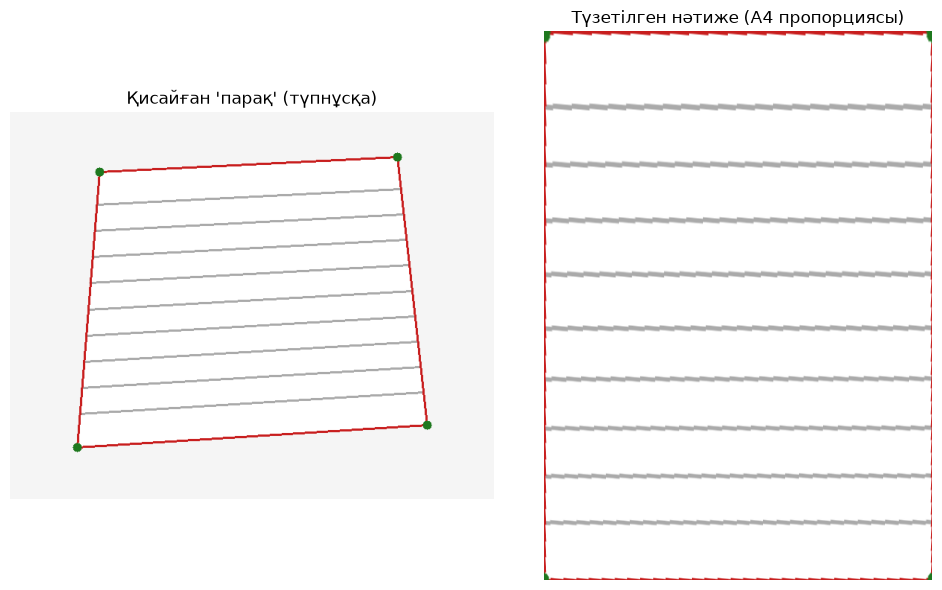

In [19]:
# Демонстрация үшін "қисайған парақ" бейнелейтін синтетикалық кескін жасаймыз
canvas = np.full((520, 650, 3), 245, dtype=np.uint8)

# Слайдтағыдай қисайған төртбұрыш бұрыштары (src)
src = np.float32([[120, 80], [520, 60], [560, 420], [90, 450]])
# A4 форматының пропорциясы (dst)
dst = np.float32([[0, 0], [420, 0], [420, 594], [0, 594]])

# "Парақтың" бетіне мәтін жолдарын елестету үшін сызықтар саламыз.
# Жолдар парақтың сол/оң жақтарына (TL-BL және TR-BR қабырғаларына) параллель
# болатындай етіп саламыз — сонда олар түзетуден кейін жазық көлденең сызықтарға айналады.
tl, tr, br, bl = src
page_poly = src.astype(np.int32)
mask = np.zeros(canvas.shape[:2], dtype=np.uint8)
cv2.fillConvexPoly(mask, page_poly, 255)
page = canvas.copy()
page[mask > 0] = (255, 255, 255)
for frac in np.linspace(0.12, 0.88, 9):
    left_pt = tl + frac * (bl - tl)
    right_pt = tr + frac * (br - tr)
    cv2.line(page, tuple(left_pt.astype(int)), tuple(right_pt.astype(int)), (170, 170, 170), 2)
cv2.polylines(page, [page_poly], isClosed=True, color=(30, 30, 200), thickness=2)
for pt in src:
    cv2.circle(page, tuple(pt.astype(int)), 6, (30, 120, 30), -1)

H = cv2.getPerspectiveTransform(src, dst)
scan = cv2.warpPerspective(page, H, (420, 594))

print("H (гомография матрицасы, 3x3):")
print(np.round(H, 5))

pt = np.float32([[[300, 250]]])
pt_new = cv2.perspectiveTransform(pt, H)
print(f"\nНүкте (300, 250) жаңа координатта: ({pt_new[0,0,0]:.1f}, {pt_new[0,0,1]:.1f})")

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
axes[0].imshow(cv2.cvtColor(page, cv2.COLOR_BGR2RGB))
axes[0].set_title("Қисайған 'парақ' (түпнұсқа)")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(scan, cv2.COLOR_BGR2RGB))
axes[1].set_title("Түзетілген нәтиже (A4 пропорциясы)")
axes[1].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "task4_perspective_transform.png"), bbox_inches="tight", dpi=120)
plt.show()


## Жалпы қорытынды

Осы семинарда түс кеңістігін түрлендіру (RGB→HSV), гистограмманы қолмен теңестіру арқылы контрастты арттыру, сонымен қатар геометриялық түрлендірулердің екі түрі — аффиндік (бұру + жылжыту, параллельдікті сақтайды) және проективті/гомографиялық (перспективаны түзетуге мүмкіндік береді, параллельдікті сақтамайды) — қарастырылды. Әр есепте қолмен есептелген нәтиже OpenCV функцияларының (`cv2.cvtColor`, `cv2.getRotationMatrix2D`, `cv2.getAffineTransform`, `cv2.getPerspectiveTransform`) нәтижесімен сәтті салыстырылды және сәйкестік расталды.